# 🐍 Python Foundations for AI
## Class 4 — Functions as AI Pipelines

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
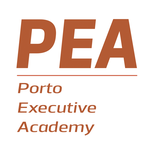
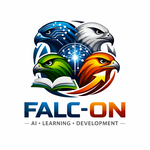
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | Why functions? |
| 2 | Defining and calling a function |
| 3 | Parameters, `return` and docstrings |
| 4 | Cleaning text — a function you will use all the time |
| 5 | Default and keyword arguments |
| 6 | Local and global — where a variable lives |
| 7 | Functions calling functions |
| 8 | 🔗 Capstone — FALC-ON AI, rebuilt with functions |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Write a function that takes values in and hands a result back
- Give parameters sensible defaults, and call a function readably
- Explain why a variable inside a function is invisible outside it
- Build an AI pipeline out of small functions that call each other

### 🤖 Why functions matter for AI

An AI application is a **pipeline**: a chain of steps, each doing one job.

```
clean the question  →  build the request  →  call the model  →  remember the answer
```

Each step is a **function**. When a step changes — a better prompt, a different model — you change **one function**, and the rest of the pipeline keeps working.

In the Class 1 capstone we promised that, in Class 9, only the "call the model" step would change. Today that step becomes a single function.

---
## 1. Why Functions?

A customer rates FALC-ON AI from 1 to 5, and we label the rating with the rules from the Class 1 flowchart. Here are two ratings, labelled with the same rules written out **twice**:

In [ ]:
rating = 5

if rating >= 4:
    print(rating, "happy")
elif rating == 3:
    print(rating, "neutral")
else:
    print(rating, "unhappy - a human should follow up")

In [ ]:
rating = 2

if rating >= 4:
    print(rating, "happy")
elif rating == 3:
    print(rating, "neutral")
else:
    print(rating, "unhappy - a human should follow up")

Three problems, and they get worse with every rating you add:

| Problem | Why it hurts |
|---------|-------------|
| The rules are written twice | Change a limit and you must remember to change every copy |
| They cannot be reused | Another notebook can only copy them |
| They cannot be tested alone | You can only check them by running everything |

A **function** fixes all three. You give the job a **name** once, and from then on you use the name:

In [ ]:
def label_rating(rating):
    """Return the label for a rating from 1 to 5."""
    if rating >= 4:
        return "happy"
    elif rating == 3:
        return "neutral"
    else:
        return "unhappy - a human should follow up"

In [ ]:
for rating in [5, 2, 3]:
    print(rating, label_rating(rating))

---
## 2. Defining and Calling a Function

You **define** a function with `def`, and nothing happens until you **call** it.

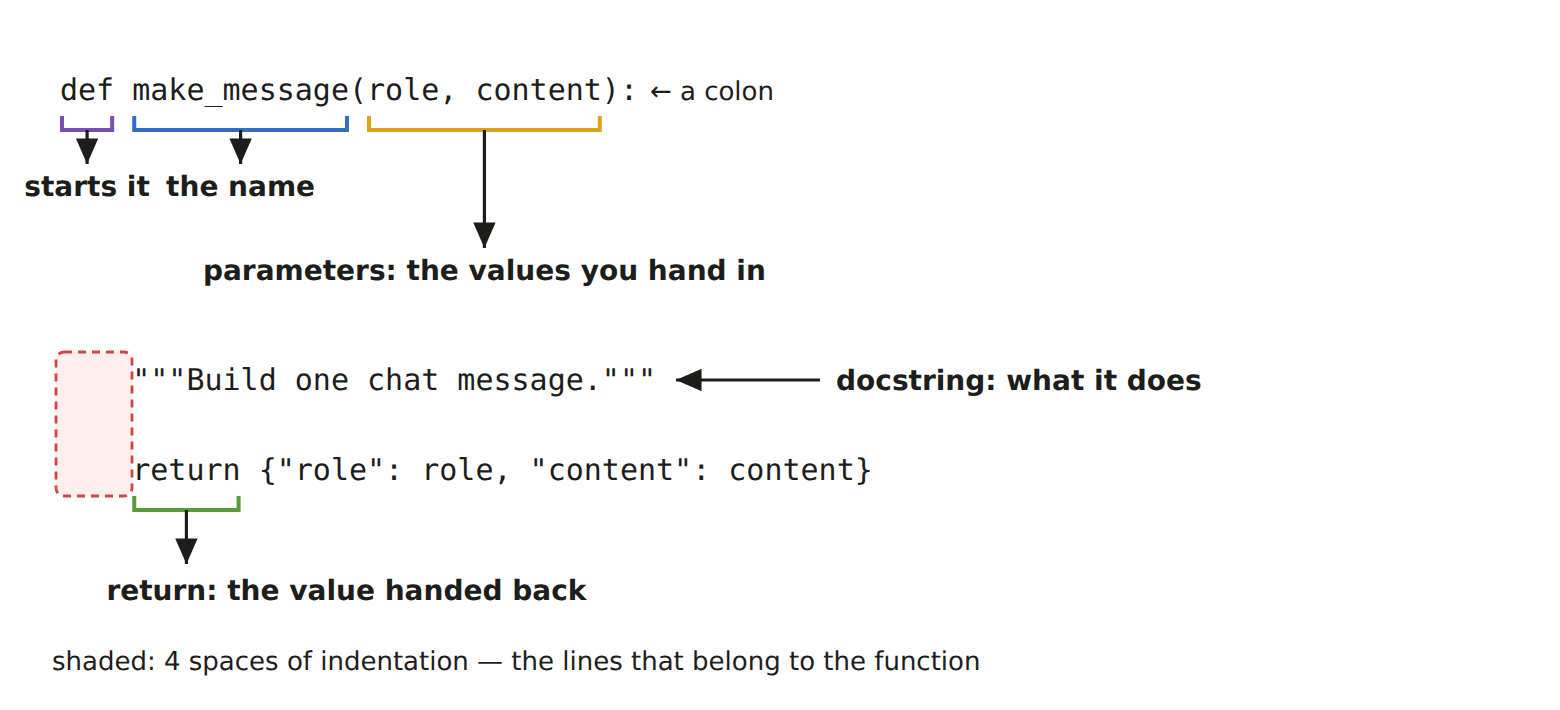

- `def`, the name, brackets with the parameters, then a **colon**
- everything that belongs to the function is **indented** underneath — the same rule as `if` and `for`
- defining it only teaches Python the job. **Calling** it, with brackets, is what runs it

In [ ]:
# Defining it - nothing happens yet
def show_banner():
    """Print the chatbot's banner."""
    print("==================")
    print("  🦅 FALC-ON AI")
    print("==================")

In [ ]:
# Calling it - now it runs, as often as we like
show_banner()

> ⚠️ `show_banner` without brackets is the function *itself*, not a call. Printing it shows something like `<function show_banner at 0x7f...>` — Python's way of telling you that you forgot the brackets.

In [ ]:
print(show_banner)

---
## 3. Parameters, `return` and Docstrings

### Parameters — the values you hand in

A **parameter** is the name a function uses for something you give it. The values you give when calling are the **arguments**.

### `return` — the value you get back

`return` hands a value back to whoever called the function, and **stops the function immediately**.

In [ ]:
def make_message(role, content):
    """Build one chat message."""
    return {"role": role, "content": content}

In [ ]:
message = make_message("user", "What is AI?")      # the returned value is kept in a variable
print(message)

### `print()` is not `return`

> ⚠️ `print()` only **shows** a value on screen. `return` **hands it back**, so you can use it. A function without `return` gives back `None` — *nothing*.

In [ ]:
def shout(text):
    """Print the text with an exclamation mark."""
    print(text + "!")

In [ ]:
result = shout("hello")          # it prints hello!...
print(result)                    # ...but hands back None

### Docstrings — what the function is for

The text in triple quotes on the first line is a **docstring**: one sentence saying what the function does. Python keeps it, and `help()` shows it.

In [ ]:
help(make_message)

---
## 4. Cleaning Text — A Function You Will Use All the Time

Users type messy text: capital letters, extra spaces. Two string methods clean it:

| Method | What it does | Example | Result |
|--------|--------------|---------|--------|
| `.lower()` | all letters to lower case | `"Hello AI".lower()` | `"hello ai"` |
| `.strip()` | removes spaces at the start and the end | `"  hi  ".strip()` | `"hi"` |

In [ ]:
question = "   How many CLASSES?  "

print(question.lower())
print(question.strip())

Spaces are invisible when you print. `len()` counts them, so you can see that `.strip()` removed them:

In [ ]:
print(len(question))              # 22 - the spaces count as characters
print(len(question.strip()))      # 17 - the 5 spaces are gone

Both at once, given a name — so the cleaning rule lives in **one place**:

In [ ]:
def clean_text(text):
    """Return the text in lower case, without spaces at the ends."""
    return text.lower().strip()

In [ ]:
print(clean_text(question))          # how many classes?
print(len(clean_text(question)))     # 17 - no spaces left

---
## 5. Default and Keyword Arguments

### Default arguments

Give a parameter a default with `=`, and the caller may leave it out. Defaults are for the **usual** case: the caller only mentions what is unusual.

> ⚠️ Parameters **with** a default must come after those without.

In [ ]:
def build_request(question, model="gemini", temperature=0.3):
    """Build a request to an AI model, with sensible defaults."""
    return {
        "model": model,
        "temperature": temperature,
        "messages": [make_message("user", question)],
    }

In [ ]:
request = build_request("What is AI?")               # only the question - defaults for the rest
print(request)

### Keyword arguments

You can **name** the arguments when you call. Then the order no longer matters, and the call explains itself:

| Call | Reads as |
|------|----------|
| `build_request("Hi", "gemini", 0.9)` | which number is which? |
| `build_request("Hi", temperature=0.9)` | obvious |

In [ ]:
request = build_request(temperature=0.9, question="Write a poem.")    # names, in any order
print(request["temperature"])                        # 0.9
print(request["model"])                              # gemini - the default

---
## 6. Local and Global — Where a Variable Lives

A variable created **outside** every function is **global**: any function can read it.

A variable created **inside** a function is **local**: it exists only while the function runs, and only in there.

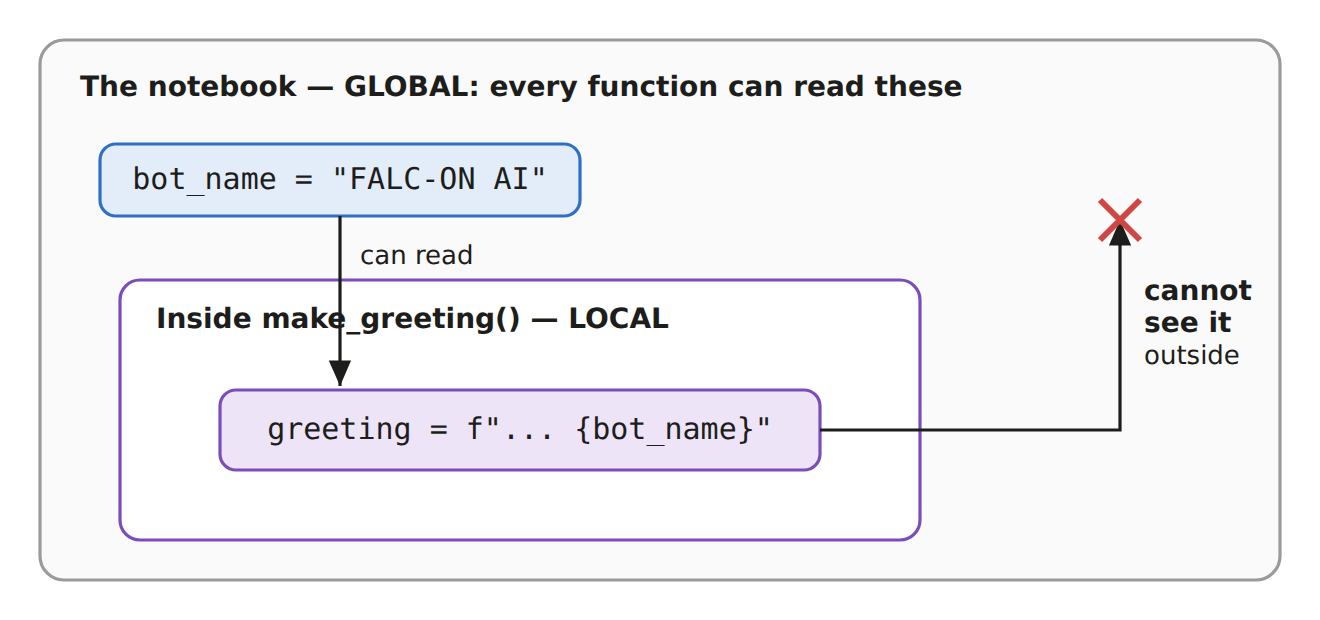

> 💡 The habit to build: **pass values in as parameters, and hand results back with `return`**. A function that works only with what it is given keeps working anywhere.

In [ ]:
bot_name = "FALC-ON AI"          # global - created outside every function

def make_greeting(user):
    """Return a greeting from the bot."""
    greeting = f"Hello {user}, I am {bot_name}!"     # local - reads the global
    return greeting

In [ ]:
print(make_greeting("Ana"))
print(bot_name)                  # the global is still here

In [ ]:
# print(greeting)   <- this would be an error: greeting only existed inside make_greeting()
print("greeting does not exist outside the function")

---
## 7. Functions Calling Functions

A function can call other functions. This is how real programs are built: small functions that each do **one** job, and one function that puts them in order.

In [ ]:
def ask(question):
    """Clean a question, and turn it into a user message."""
    cleaned = clean_text(question)
    return make_message("user", cleaned)

In [ ]:
print(ask("   What is AI?  "))

### A function that builds a list

Start from an **empty list** `[]`, append to it in a loop, and `return` the finished list.

In [ ]:
def build_history(questions):
    """Return a conversation with one user message per question."""
    history = []                                 # an empty list
    for question in questions:
        history.append(ask(question))
    return history

In [ ]:
history = build_history(["Hi!", "  What is PYTHON? "])
print(len(history))                              # 2
print(history)

> 💡 **The test of a good function:** you can say what it does in one sentence, without the word "and". `clean_text()` cleans text. A function that cleans *and* answers *and* saves should be three functions.

---
## 8. 🔗 Capstone — FALC-ON AI, Rebuilt with Functions

In Class 2, FALC-ON AI was one long loop. Today each step becomes a small function, and one function, `chat_turn()`, puts them in order:

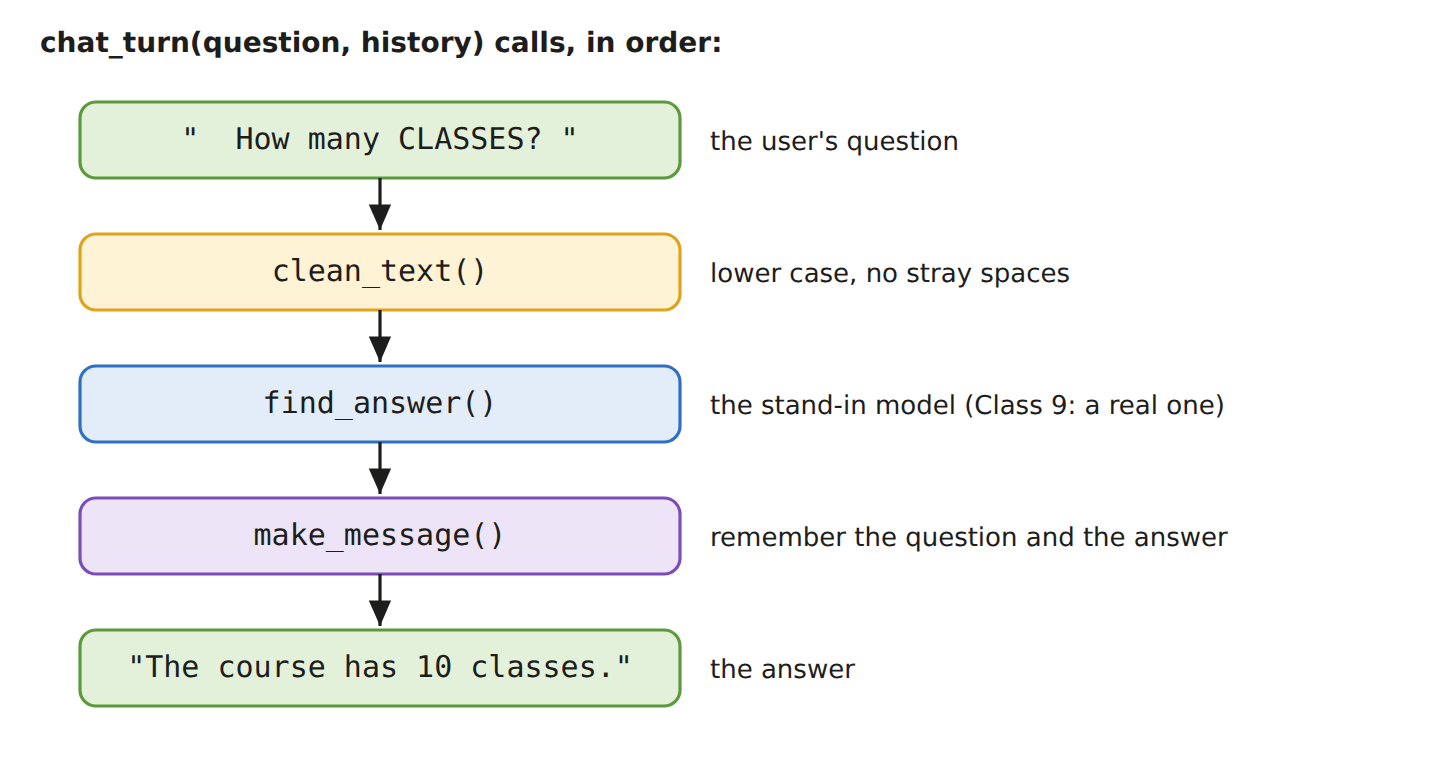

`find_answer()` is the **stand-in model**. In Class 9 it becomes a call to a real AI model — and it is the **only** function that changes.

### Step 1 — The stand-in model

It looks for a keyword in the question and returns its answer.

> 💡 A `return` inside the loop stops the whole function straight away: the first keyword found wins. If none is found, the loop ends and the last line runs.

In [ ]:
knowledge = {
    "class": "The course has 10 classes.",
    "teach": "Alexandra Oliveira and Catarina Santos teach this course.",
    "colab": "We write our code in Google Colab.",
}

def find_answer(question):
    """The stand-in model: answer from the knowledge dictionary."""
    for keyword in knowledge:
        if keyword in question:
            return knowledge[keyword]
    return "Sorry, I don't know that yet."

In [ ]:
print(find_answer("who teaches this course?"))

### Step 2 — One turn of the conversation

One turn is everything an assistant does between receiving a question and giving its answer. `chat_turn()` does it in four steps, and each one is there for a reason:

| Line | What it does | Why it is needed |
|------|--------------|------------------|
| `question = clean_text(question)` | puts the question in lower case, without spaces at the ends | users type *"  How many CLASSES?"*, but the keywords are lower case: without cleaning, the stand-in finds nothing |
| `answer = find_answer(question)` | asks the stand-in model | this is the step the model does — the only one that changes in Class 9 |
| `history.append(make_message("user", question))` | remembers the question | a model remembers nothing between questions: the **app** keeps the conversation, in the message shape from Class 2 |
| `history.append(make_message("assistant", answer))` | remembers the answer | so the whole conversation, questions **and** answers, can be sent to the model, saved, or reviewed later |
| `return answer` | hands the answer back | `chat_turn()` does not decide how the answer is shown: the caller prints it in a chat, puts it on a web page, or saves it |

> 💡 A list passed into a function can be changed by it: `.append()` adds to the **same** list the caller has.

In [ ]:
def chat_turn(question, history):
    """Answer one question, and remember both messages."""
    question = clean_text(question)
    answer = find_answer(question)
    history.append(make_message("user", question))
    history.append(make_message("assistant", answer))
    return answer

The conversation starts with a **system message**: the instructions for the model, which it reads before every question (Class 2). After one turn, `history` holds three messages.

In [ ]:
history = [make_message("system", "You are a course assistant. Answer in one short sentence.")]

print(chat_turn("   How many CLASSES?  ", history))
print(len(history))              # 3 - the system message, the question, the answer

### Step 3 — The conversation

The whole chatbot is now a few lines — and, thanks to `clean_text()`, capital letters and extra spaces no longer matter.

> 💡 Try: *"How many CLASSES?"*, *"Who teaches?"*, *"is there homework?"*, then *"bye"*.

In [ ]:
show_banner()

while True:
    question = input("You: ")
    if clean_text(question) == "bye":
        print("FALC-ON AI: Goodbye! Keep coding!")
        break
    print(f"FALC-ON AI: {chat_turn(question, history)}")

---

### 🎉 That's Class 4!

| Concept | Key syntax |
|---------|------------|
| Define a function | `def make_message(role, content):` |
| Call it | `make_message("user", "Hi")` |
| Hand a value back | `return {...}` |
| Describe it | `"""One sentence saying what it does."""`, `help()` |
| No `return` | the function gives back `None` |
| Clean text | `.lower()`, `.strip()` |
| Default argument | `def build_request(question, model="gemini"):` |
| Keyword argument | `build_request(question="Hi", temperature=0.9)` |
| Local variable | created inside, invisible outside |
| Global variable | created outside, readable inside |
| Functions calling functions | `chat_turn()` calls `clean_text()`, `find_answer()`, `make_message()` |
| Build a list | `history = []`, `.append()`, `return history` |

> 🤖 **The big picture:** FALC-ON AI is now a pipeline of small functions. In Class 9, `find_answer()` becomes a call to a real AI model — and nothing else needs to change. In Class 5 you will learn shorter ways to write loops like the one in `build_history()`.

➡️ Now open the **exercises notebook**.